In [1]:
# Lab 1 - image enhancement (Vedere artificiala) - Stefan-Teodor Iancu
import sys

import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [2]:
# OpenCV stores BGR, matplotlib wants RGB
def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# Show a list of (title, image) as a grid of subplots
def show_grid(items, cols, title=None, cell=3.0):
    rows = int(np.ceil(len(items) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(cols * cell, rows * cell))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs:
        ax.axis('off')
    for ax, (label, img) in zip(axs, items):
        ax.imshow(to_rgb(img), cmap='gray' if img.ndim == 2 else None)
        ax.set_title(label, fontsize=9)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# Markdown table from a list of dicts that all have the same keys
def show_table(rows):
    keys = list(rows[0].keys())
    lines = ['| ' + ' | '.join(keys) + ' |', '|' + '---|' * len(keys)]
    for r in rows:
        lines.append('| ' + ' | '.join(str(r[k]) for k in keys) + ' |')
    display(Markdown('\n'.join(lines)))

### 1. **Install OpenCV**

OpenCV is installed in the course virtual environment (`.venv`), together with numpy and matplotlib.

In [3]:
print('cv2.__version__ =', cv2.__version__)
print('numpy', np.__version__, '| matplotlib', matplotlib.__version__, '| python', sys.version.split()[0])

cv2.__version__ = 5.0.0
numpy 2.5.4 | matplotlib 3.11.2 | python 3.12.14


OpenCV **5.0.0** works (numpy 2.5.4, matplotlib 3.11.2, Python 3.12).

---

### 2. **Open lena.tif, display its size, plot it**

height=512  width=512  channels=3  dtype=uint8  (img.shape = (512, 512, 3))


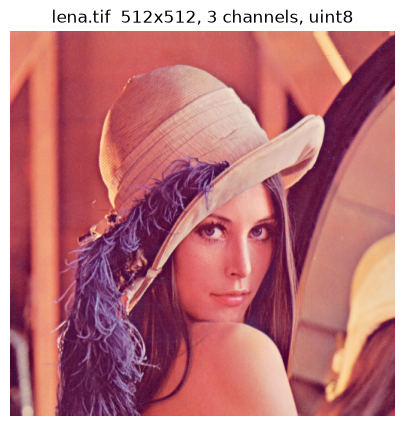

In [4]:
lena = cv2.imread('lena.tif', cv2.IMREAD_COLOR)
assert lena is not None, 'lena.tif not found next to the notebook'

h, w, c = lena.shape
print(f'height={h}  width={w}  channels={c}  dtype={lena.dtype}  (img.shape = {lena.shape})')

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(to_rgb(lena))
ax.set_title(f'lena.tif  {w}x{h}, {c} channels, {lena.dtype}')
ax.axis('off')
plt.show()

`img.shape = (512, 512, 3)`: height 512, width 512, 3 channels (OpenCV keeps them in BGR order), dtype `uint8`.

---

### 3. **Filters that blur and sharpen the image**

Every filter that has a parameter is run with at least 2 values. The first value of each filter is
the one used in the lab notebook ("Types of noise. Filters.").

- **blur**: mean (box) filter, average of the k x k window
- **GaussianBlur**: weighted average, sigma = 0 lets OpenCV pick sigma from k
- **medianBlur**: median of the window (non-linear)
- **bilateralFilter**: blurs but keeps edges
- **sharpen**: convolution (`filter2D`) with a sharpening kernel
- **unsharp masking**: original + amount * (original - blurred)

18 filtered images


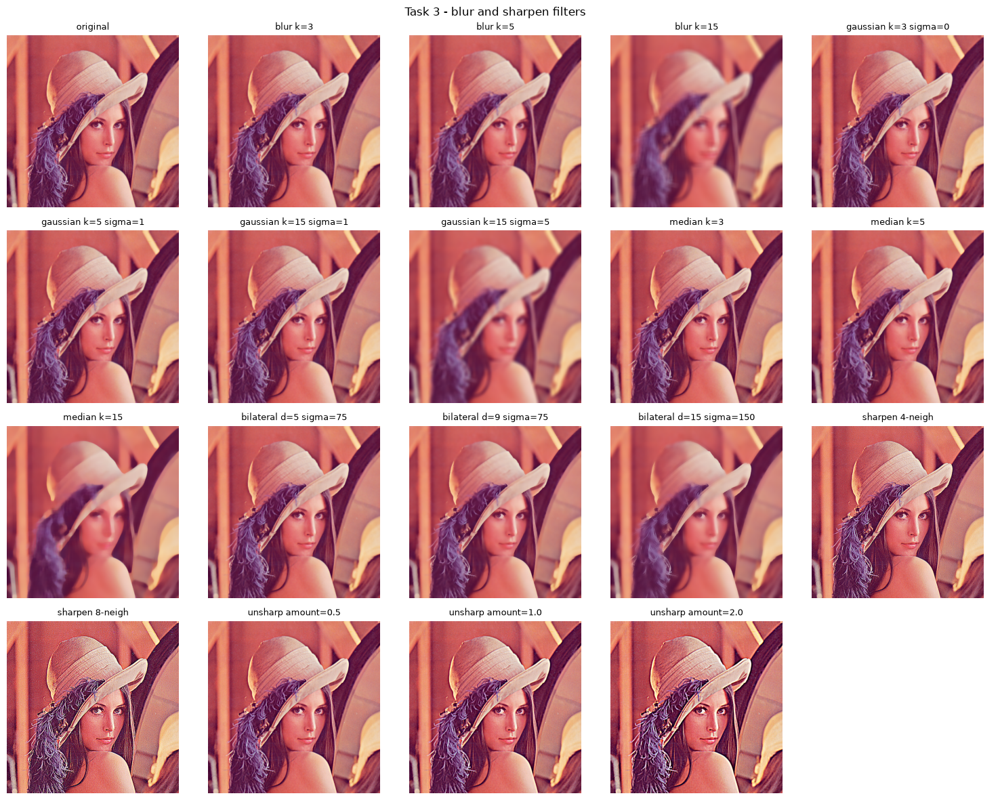

In [5]:
results = [('original', lena)]

# mean filter (box)
for k in (3, 5, 15):
    results.append((f'blur k={k}', cv2.blur(lena, (k, k))))

# gaussian: kernel size and sigma (0 = auto)
for k, s in ((3, 0), (5, 1), (15, 1), (15, 5)):
    results.append((f'gaussian k={k} sigma={s}', cv2.GaussianBlur(lena, (k, k), s)))

# median: good against salt & pepper noise
for k in (3, 5, 15):
    results.append((f'median k={k}', cv2.medianBlur(lena, k)))

# bilateral: blurs but keeps edges
for d, s in ((5, 75), (9, 75), (15, 150)):
    results.append((f'bilateral d={d} sigma={s}', cv2.bilateralFilter(lena, d, s, s)))

sharpen_kernels = {
    'sharpen 4-neigh': np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32),
    'sharpen 8-neigh': np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], np.float32),
}
for label, kernel in sharpen_kernels.items():
    results.append((label, cv2.filter2D(lena, -1, kernel)))

# Unsharp mask: original + amount * (original - blurred)
blurred = cv2.GaussianBlur(lena, (9, 9), 10.0)
for amount in (0.5, 1.0, 2.0):
    unsharp_image = cv2.addWeighted(lena, 1 + amount, blurred, -amount, 0)
    results.append((f'unsharp amount={amount}', unsharp_image))

print(len(results) - 1, 'filtered images')
show_grid(results, cols=5, title='Task 3 - blur and sharpen filters')

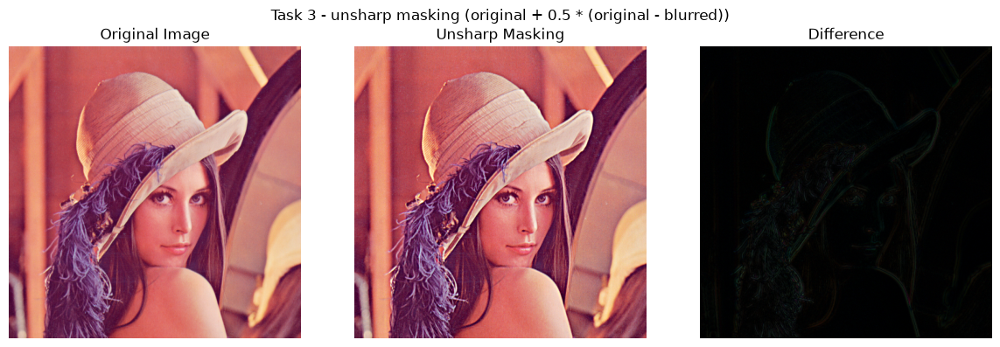

In [6]:
# Unsharp masking exactly like in the lab notebook: 1.5 * original - 0.5 * blurred
unsharp_image = cv2.addWeighted(lena, 1.5, blurred, -0.5, 0)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(to_rgb(lena))
axs[0].set_title('Original Image')
axs[1].imshow(to_rgb(unsharp_image))
axs[1].set_title('Unsharp Masking')
axs[2].imshow(to_rgb(cv2.absdiff(unsharp_image, lena)))
axs[2].set_title('Difference')
for ax in axs:
    ax.axis('off')
fig.suptitle('Task 3 - unsharp masking (original + 0.5 * (original - blurred))')
plt.tight_layout()
plt.show()

- Mean blur: k=3 is barely visible, k=5 only softens, k=15 is very blurry. Gaussian: sigma controls the blur,
  k only has to be big enough (about 6 * sigma), so with sigma=1 a bigger kernel changes almost nothing.
- Median looks "painted" but keeps edges sharper than the box blur (k=15 removes the feathers);
  bilateral smooths the skin and keeps edges, (15, 150) looks like a cartoon.
- The 8-neighbour sharpen kernel is much stronger than the 4-neighbour one and shows the noise.
- Unsharp masking: amount 0.5 (= the notebook's 1.5 / -0.5) is subtle, 1 looks natural, 2 gives halos.
  The difference uses `cv2.absdiff`, so it does not wrap around like a plain uint8 subtraction.

#### 3.1 **Types of noise and the filter that fits each one**

Noise generators written like in the lab notebook, applied on gray lena with `np.random.seed(0)`.
Each noise is paired with the filter the notebook uses for it. PSNR is measured against the clean image
(higher = closer to the original).

In [7]:
def add_gaussian_noise(image, mean=0, var=0.01):
    sigma = var ** 0.5
    noisy_image = image + np.random.normal(mean, sigma, image.shape) * 255
    noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)
    return noisy_image


def add_salt_and_pepper_noise(image, amount=0.05):
    noisy_image = np.copy(image)
    salt = np.ceil(amount * image.size * 0.5)
    pepper = np.ceil(amount * image.size * 0.5)

    coords = [np.random.randint(0, i - 1, int(salt)) for i in image.shape]
    noisy_image[coords[0], coords[1]] = 255

    coords = [np.random.randint(0, i - 1, int(pepper)) for i in image.shape]
    noisy_image[coords[0], coords[1]] = 0
    return noisy_image


def add_poisson_noise(image):
    noisy_image = np.random.poisson(image / 255.0 * 10) / 10 * 255
    noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)
    return noisy_image


def add_speckle_noise(image):
    noise = np.random.randn(*image.shape)
    noisy_image = image + image * noise
    noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)
    return noisy_image

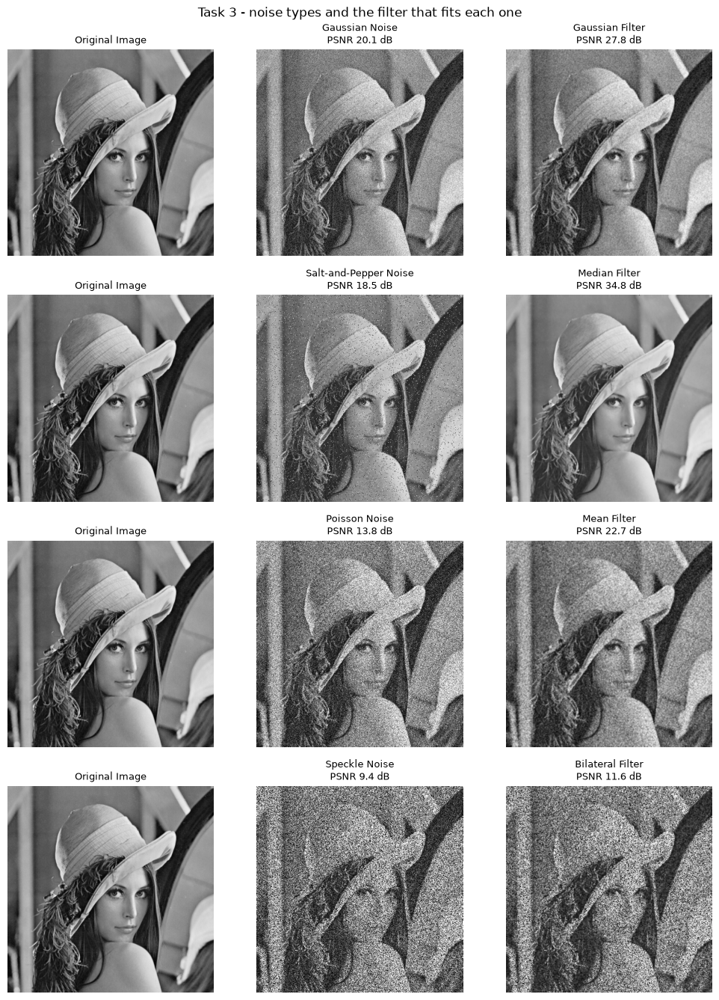

| noise | filter | PSNR noisy (dB) | PSNR filtered (dB) |
|---|---|---|---|
| Gaussian Noise | Gaussian Filter | 20.1 | 27.8 |
| Salt-and-Pepper Noise | Median Filter | 18.5 | 34.8 |
| Poisson Noise | Mean Filter | 13.8 | 22.7 |
| Speckle Noise | Bilateral Filter | 9.4 | 11.6 |

In [8]:
np.random.seed(0)
image = cv2.cvtColor(lena, cv2.COLOR_BGR2GRAY)

gaussian_noisy = add_gaussian_noise(image)
salt_pepper_noisy = add_salt_and_pepper_noise(image)
poisson_noisy = add_poisson_noise(image)
speckle_noisy = add_speckle_noise(image)

gaussian_filtered = cv2.GaussianBlur(gaussian_noisy, (3, 3), 0)
median_filtered = cv2.medianBlur(salt_pepper_noisy, 3)
mean_filtered = cv2.blur(poisson_noisy, (3, 3))
bilateral_filtered = cv2.bilateralFilter(speckle_noisy, 5, 75, 75)

pairs = [('Gaussian Noise', gaussian_noisy, 'Gaussian Filter', gaussian_filtered),
         ('Salt-and-Pepper Noise', salt_pepper_noisy, 'Median Filter', median_filtered),
         ('Poisson Noise', poisson_noisy, 'Mean Filter', mean_filtered),
         ('Speckle Noise', speckle_noisy, 'Bilateral Filter', bilateral_filtered)]

items, rows = [], []
for noise_name, noisy, filter_name, filtered in pairs:
    psnr_noisy = cv2.PSNR(image, noisy)
    psnr_filtered = cv2.PSNR(image, filtered)
    items += [('Original Image', image),
              (f'{noise_name}\nPSNR {psnr_noisy:.1f} dB', noisy),
              (f'{filter_name}\nPSNR {psnr_filtered:.1f} dB', filtered)]
    rows.append({'noise': noise_name, 'filter': filter_name,
                 'PSNR noisy (dB)': round(psnr_noisy, 1), 'PSNR filtered (dB)': round(psnr_filtered, 1)})

show_grid(items, cols=3, title='Task 3 - noise types and the filter that fits each one', cell=3.4)
show_table(rows)

- Salt-and-pepper + median 3: **18.5 -> 34.8 dB**, the dots disappear completely and the edges stay sharp (best pair).
- Gaussian noise + `GaussianBlur (3,3)`: 20.1 -> 27.8 dB, the grain is softened, the image gets a bit blurry.
- Poisson + mean `blur (3,3)`: 13.8 -> 22.7 dB, still grainy; a 3x3 window is small for this much noise.
- Speckle + bilateral `5,75,75`: 9.4 -> 11.6 dB, the notebook's speckle is very strong (`randn` std 1), the filter barely helps.
- Mean and Gaussian are averages, so they blur edges; the median is non-linear and keeps them.

#### 3.2 **Contrast enhancement: gamma, histogram equalization, CLAHE**

The other enhancement family from the lab notebook. Gamma correction is applied with a 256-entry lookup table (`cv2.LUT`).

In [9]:
def gamma_correction(image, gamma=1.0):
    invGamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** invGamma) * 255 for i in np.arange(0, 256)]).astype('uint8')
    return cv2.LUT(image, table)


# equalize only the brightness: V channel of HSV
def equalize_hsv_value(img_bgr):
    h, s, v = cv2.split(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV))
    return cv2.cvtColor(cv2.merge((h, s, cv2.equalizeHist(v))), cv2.COLOR_HSV2BGR)


# equalize only the lightness: L channel of LAB (plain equalizeHist or CLAHE)
def equalize_lab_lightness(img_bgr, clahe=None):
    l, a, b = cv2.split(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB))
    l_new = clahe.apply(l) if clahe is not None else cv2.equalizeHist(l)
    return cv2.cvtColor(cv2.merge((l_new, a, b)), cv2.COLOR_LAB2BGR)

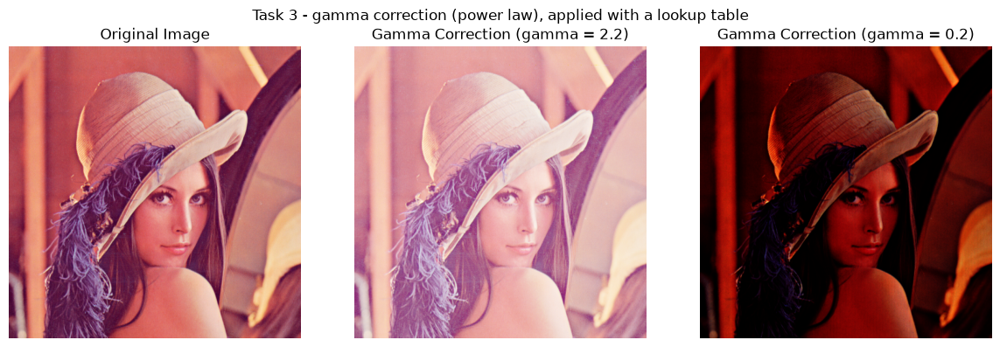

In [10]:
gamma_img = gamma_correction(lena, gamma=2.2)
gamma_img_subunitar = gamma_correction(lena, gamma=0.2)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(to_rgb(lena))
axs[0].set_title('Original Image')
axs[1].imshow(to_rgb(gamma_img))
axs[1].set_title('Gamma Correction (gamma = 2.2)')
axs[2].imshow(to_rgb(gamma_img_subunitar))
axs[2].set_title('Gamma Correction (gamma = 0.2)')
for ax in axs:
    ax.axis('off')
fig.suptitle('Task 3 - gamma correction (power law), applied with a lookup table')
plt.tight_layout()
plt.show()

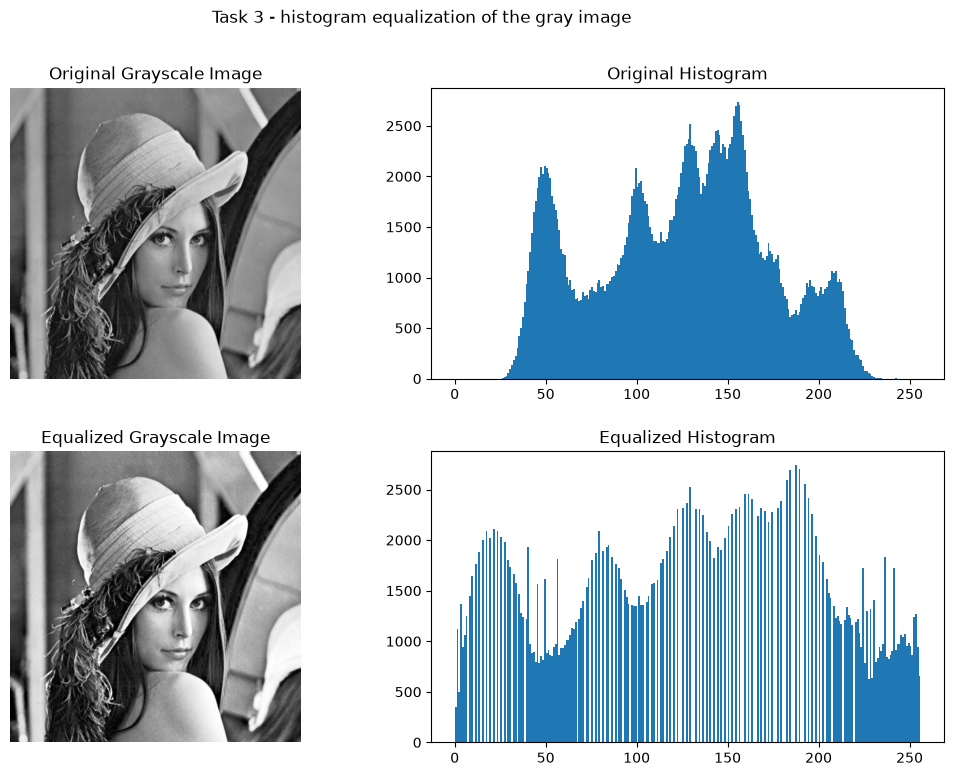

In [11]:
img_gray = cv2.cvtColor(lena, cv2.COLOR_BGR2GRAY)
equalized_img = cv2.equalizeHist(img_gray)

fig, axs = plt.subplots(2, 2, figsize=(11, 8))
axs[0, 0].imshow(img_gray, cmap='gray')
axs[0, 0].set_title('Original Grayscale Image')
axs[0, 1].hist(img_gray.ravel(), 256, range=[0, 256])
axs[0, 1].set_title('Original Histogram')
axs[1, 0].imshow(equalized_img, cmap='gray')
axs[1, 0].set_title('Equalized Grayscale Image')
axs[1, 1].hist(equalized_img.ravel(), 256, range=[0, 256])
axs[1, 1].set_title('Equalized Histogram')
axs[0, 0].axis('off')
axs[1, 0].axis('off')
fig.suptitle('Task 3 - histogram equalization of the gray image')
plt.tight_layout(pad=2.0)
plt.show()

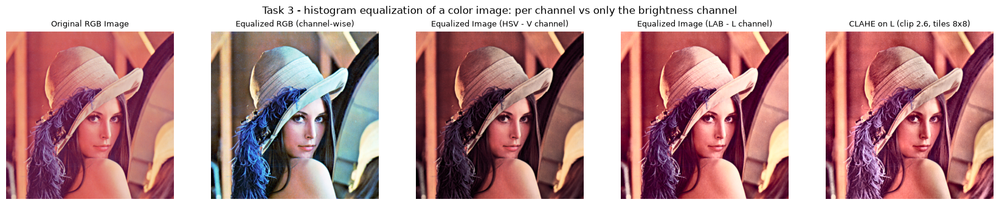

mean intensity: original 124.0, gamma 2.2 176.3, gamma 0.2 29.5, equalized gray 128.3


In [12]:
b, g, r = cv2.split(lena)
img_rgb_equalized = cv2.merge((cv2.equalizeHist(b), cv2.equalizeHist(g), cv2.equalizeHist(r)))
img_equalized_hsv = equalize_hsv_value(lena)
img_equalized_lab = equalize_lab_lightness(lena)
clahe = cv2.createCLAHE(clipLimit=2.6, tileGridSize=(8, 8))
img_clahe = equalize_lab_lightness(lena, clahe)

color_items = [('Original RGB Image', lena),
               ('Equalized RGB (channel-wise)', img_rgb_equalized),
               ('Equalized Image (HSV - V channel)', img_equalized_hsv),
               ('Equalized Image (LAB - L channel)', img_equalized_lab),
               ('CLAHE on L (clip 2.6, tiles 8x8)', img_clahe)]
show_grid(color_items, cols=5, cell=3.4,
          title='Task 3 - histogram equalization of a color image: per channel vs only the brightness channel')

print('mean intensity: original %.1f, gamma 2.2 %.1f, gamma 0.2 %.1f, equalized gray %.1f'
      % (img_gray.mean(), cv2.cvtColor(gamma_img, cv2.COLOR_BGR2GRAY).mean(),
         cv2.cvtColor(gamma_img_subunitar, cv2.COLOR_BGR2GRAY).mean(), equalized_img.mean()))

- Gamma 2.2 brightens lena (mean 124 -> 176) and gamma 0.2 darkens it (mean -> 30); the table uses `1 / gamma`, so here gamma > 1 brightens.
- `cv2.equalizeHist` spreads the gray histogram over 0..255 (mean 124 -> 128, the histogram becomes almost flat).
- On the color image, equalizing R, G and B separately shifts the colors (lena turns blue-ish).
  Equalizing only V (HSV) or L (LAB) keeps the colors and adds contrast.
- CLAHE on L (`clipLimit=2.6, tileGridSize=(8,8)`) adds local contrast without blowing out the bright hat.

---

### 4. **The kernel w = [[-1, -1, -1], [-1, 8 + a, -1], [-1, -1, -1]], a in [0, 2]**

Tested a = 0, 0.5, 1, 1.5, 2 on 3 images: `lena.tif`, `images/group.jpg` (bright, white background) and
`images/manwoman.jpg` (dark), the last two taken from Lab 2. The sum of the kernel is `a`, so the result is
`a * image + edges`.

lena      (512, 512, 3)  original mean intensity 128.2
group     (282, 425, 3)  original mean intensity 169.6
manwoman  (358, 477, 3)  original mean intensity 57.5


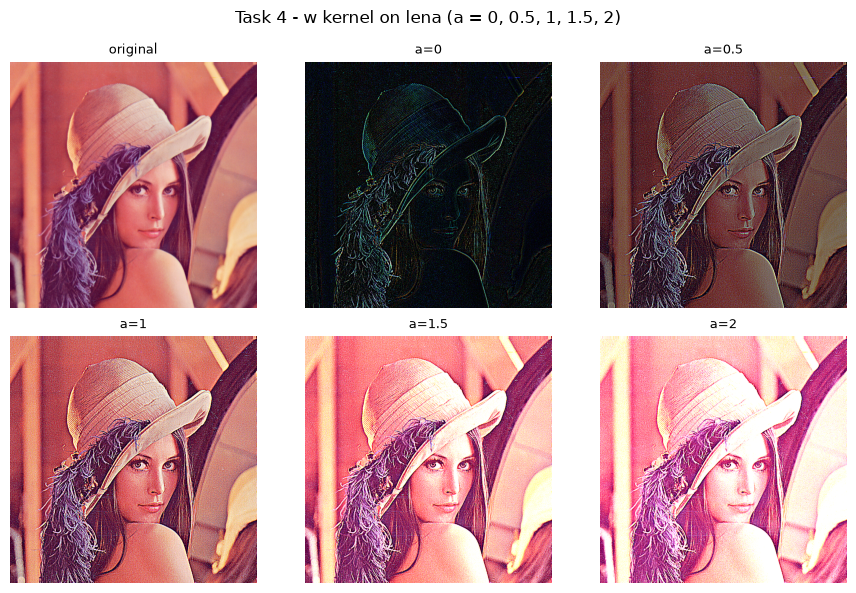

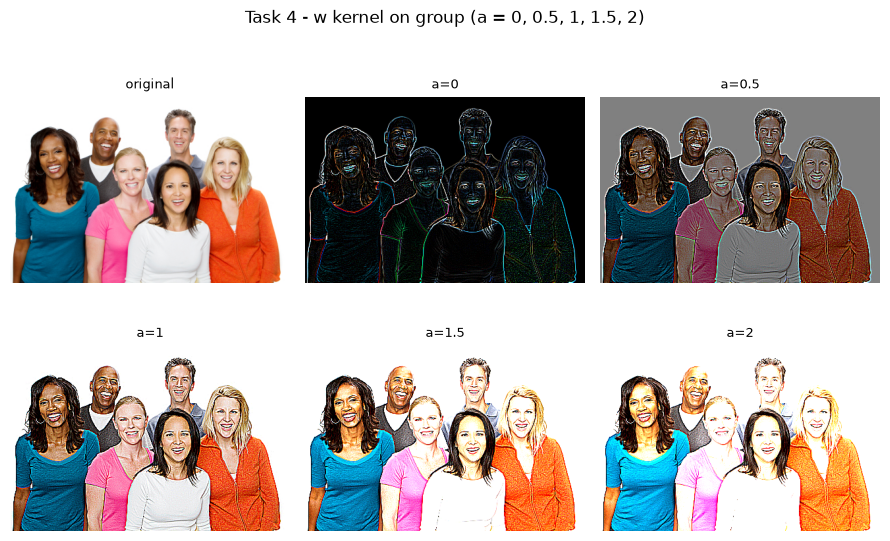

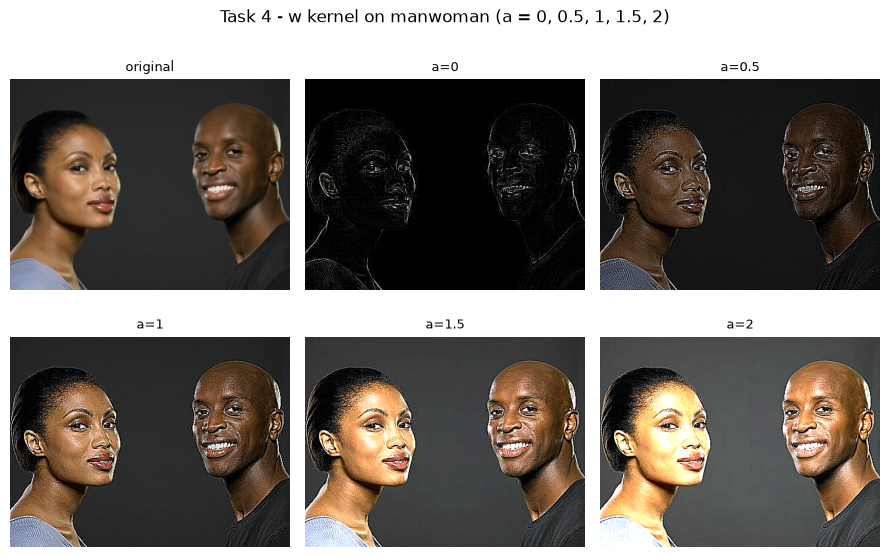

In [13]:
def make_w(a):
    return np.array([[-1, -1, -1], [-1, 8 + a, -1], [-1, -1, -1]], dtype=np.float32)


test_images = {'lena': lena,
               'group': cv2.imread('images/group.jpg'),
               'manwoman': cv2.imread('images/manwoman.jpg')}
for name, img in test_images.items():
    print(f'{name:9s} {img.shape}  original mean intensity {img.mean():.1f}')

a_values = [0, 0.5, 1, 1.5, 2]
rows = []
for img_name, img in test_images.items():
    items = [('original', img)]
    for a in a_values:
        w = make_w(a)
        res = cv2.filter2D(img, -1, w)                # ddepth=-1 -> uint8, values saturated to [0,255]
        res_f = cv2.filter2D(img, cv2.CV_32F, w)      # float output, nothing is clipped
        items.append((f'a={a}', res))
        gray = cv2.cvtColor(res, cv2.COLOR_BGR2GRAY)
        rows.append({
            'image': img_name,
            'a': a,
            'kernel sum': round(float(w.sum()), 2),
            'mean intensity': round(float(res.mean()), 1),
            '% pixels = 0': round(float((res == 0).mean() * 100), 1),
            '% pixels = 255': round(float((res == 255).mean() * 100), 1),
            'sharpness (var. Laplacian)': int(round(float(cv2.Laplacian(gray, cv2.CV_64F).var()), 0)),
            'float range': f'[{res_f.min():.0f}, {res_f.max():.0f}]',
        })
    show_grid(items, cols=3, title=f'Task 4 - w kernel on {img_name} (a = 0, 0.5, 1, 1.5, 2)')

In [14]:
show_table(rows)

| image | a | kernel sum | mean intensity | % pixels = 0 | % pixels = 255 | sharpness (var. Laplacian) | float range |
|---|---|---|---|---|---|---|---|
| lena | 0 | 0.0 | 17.2 | 51.3 | 0.3 | 8586 | [-990, 737] |
| lena | 0.5 | 0.5 | 69.2 | 13.6 | 0.8 | 15598 | [-984, 832] |
| lena | 1 | 1.0 | 129.1 | 6.2 | 4.0 | 18849 | [-978, 928] |
| lena | 1.5 | 1.5 | 173.0 | 3.7 | 31.5 | 18624 | [-972, 1024] |
| lena | 2 | 2.0 | 199.5 | 2.5 | 47.6 | 16126 | [-966, 1119] |
| group | 0 | 0.0 | 14.2 | 62.8 | 0.8 | 10165 | [-832, 1036] |
| group | 0.5 | 0.5 | 91.4 | 13.8 | 1.8 | 14686 | [-814, 1155] |
| group | 1 | 1.0 | 170.3 | 10.2 | 37.1 | 16110 | [-798, 1274] |
| group | 1.5 | 1.5 | 191.9 | 8.5 | 59.0 | 14812 | [-785, 1393] |
| group | 2 | 2.0 | 203.4 | 7.3 | 66.7 | 13537 | [-772, 1512] |
| manwoman | 0 | 0.0 | 6.4 | 69.1 | 0.2 | 3911 | [-605, 1536] |
| manwoman | 0.5 | 0.5 | 31.3 | 8.4 | 0.4 | 6256 | [-562, 1650] |
| manwoman | 1 | 1.0 | 58.6 | 5.0 | 1.0 | 7251 | [-534, 1765] |
| manwoman | 1.5 | 1.5 | 85.0 | 3.6 | 4.3 | 7126 | [-507, 1880] |
| manwoman | 2 | 2.0 | 107.8 | 2.8 | 9.8 | 6488 | [-480, 1994] |

**Which a gave the best result, in my opinion: a = 1.** The kernel then sums to 1, so the brightness stays the
same as the original and only the edges are boosted (classic sharpening, the unsharp-masking idea). On all three
images it still looks natural and the sharpness is the highest or very close to it.
- a = 0 is an edge detector, not an enhancement: almost black image, 51-69 % of the pixels are 0.
- a = 0.5 halves the brightness, the image looks gray and flat.
- a = 1.5 and 2 brighten more and more: on the bright `group` image 59-67 % of the pixels saturate at 255.
  On the dark `manwoman` image a = 1.5 is still fine, so the best a depends a little on how bright the image is.

#### 4.1 **ddepth = -1 (uint8) vs a float output, for a = 0**

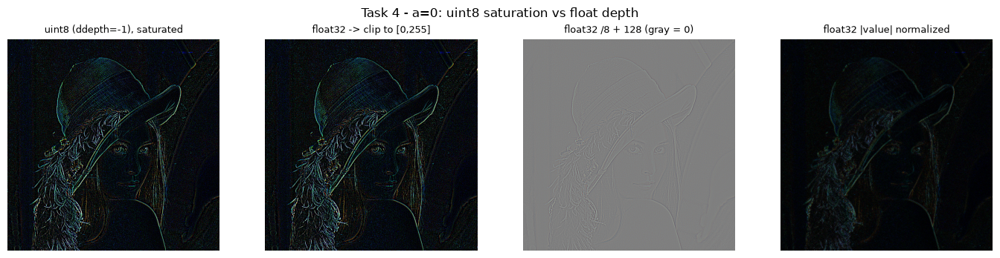

float output range for a=0 on lena: [-990, 737]; 50.2% of values are outside 0..255
uint8 result == float result clipped+rounded: True


In [15]:
res_u8 = cv2.filter2D(lena, -1, make_w(0))
res_f = cv2.filter2D(lena, cv2.CV_32F, make_w(0))
clipped = np.clip(np.rint(res_f), 0, 255).astype(np.uint8)        # manual saturation == ddepth=-1
shifted = np.clip(res_f / 8 + 128, 0, 255).astype(np.uint8)       # gray = 0, dark = negative, bright = positive
abs_norm = cv2.normalize(np.abs(res_f), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

show_grid([('uint8 (ddepth=-1), saturated', res_u8),
           ('float32 -> clip to [0,255]', clipped),
           ('float32 /8 + 128 (gray = 0)', shifted),
           ('float32 |value| normalized', abs_norm)],
          cols=4, title='Task 4 - a=0: uint8 saturation vs float depth', cell=3.5)

print(f'float output range for a=0 on lena: [{res_f.min():.0f}, {res_f.max():.0f}]; '
      f'{((res_f < 0) | (res_f > 255)).mean() * 100:.1f}% of values are outside 0..255')
print('uint8 result == float result clipped+rounded:', np.array_equal(res_u8, clipped))

With `ddepth=-1` the output stays uint8 and OpenCV saturates (below 0 -> 0, above 255 -> 255). With `cv2.CV_32F`
nothing is clipped: for a = 0 on lena the values are in **[-990, 737]** and **50.2 %** of them are outside 0..255.
The uint8 result is exactly the float result after `np.rint` + `np.clip(0, 255)` (`np.array_equal` -> True).
A float result has to be clipped, shifted (`value/8 + 128`, which also shows the negative side of the edges) or
normalized before it can be shown.

---

### 5. **Rotation with arbitrary angles, clockwise and counterclockwise**

Positive angle = counterclockwise, negative angle = clockwise (OpenCV convention). The rotation center is
`(cols // 2, rows // 2)` like in the lab notebook.

#### Helpers: own rotation written only with numpy (inverse mapping)

1. Build the 2x3 affine matrix `M` that rotates around the image center (same as `cv2.getRotationMatrix2D`).
2. For every pixel `(x, y)` of the OUTPUT compute where it comes from in the INPUT: `(sx, sy) = M^-1 * (x, y, 1)`.
   Going backwards guarantees that every output pixel gets a value; forward mapping would leave holes.
3. `(sx, sy)` is almost never an integer, so interpolate: nearest neighbour (closest pixel) or bilinear
   (weighted average of the 4 pixels around it).
4. Output pixels whose source falls outside the input stay black (like `BORDER_CONSTANT = 0` in `cv2.warpAffine`).

In [16]:
# Same 2x3 matrix as cv2.getRotationMatrix2D(center, angle, scale)
def rotation_matrix(angle_deg, center, scale=1.0):
    a = np.deg2rad(angle_deg)
    alpha = scale * np.cos(a)
    beta = scale * np.sin(a)
    cx, cy = center
    return np.array(
        [[alpha, beta, (1 - alpha) * cx - beta * cy],
         [-beta, alpha, beta * cx + (1 - alpha) * cy]],
        dtype=np.float64,
    )


# Invert a 2x3 affine matrix (add the row [0 0 1], invert, drop it)
def invert_affine(M):
    M3 = np.vstack([M, [0.0, 0.0, 1.0]])
    return np.linalg.inv(M3)[:2]


# Size of the smallest canvas that contains the whole rotated image
def rotated_canvas_size(w, h, angle_deg):
    a = np.deg2rad(angle_deg)
    new_w = int(np.ceil(abs(w * np.cos(a)) + abs(h * np.sin(a))))
    new_h = int(np.ceil(abs(w * np.sin(a)) + abs(h * np.cos(a))))
    return new_w, new_h


# Center used for the rotation, (x, y) = (cols // 2, rows // 2) like in the lab notebook
def image_center(img):
    h, w = img.shape[:2]
    return (w // 2, h // 2)


# Rotate img by angle_deg degrees around its center.
# interpolation: 'nearest' or 'bilinear'
# keep_all: False -> same size as the input (corners are cut), True -> bigger canvas, nothing is cut
def rotate_numpy(img, angle_deg, interpolation='bilinear', keep_all=False):
    h, w = img.shape[:2]
    M = rotation_matrix(angle_deg, image_center(img))

    out_w, out_h = w, h
    if keep_all:
        out_w, out_h = rotated_canvas_size(w, h, angle_deg)
        # shift the result so the rotated image is centered in the bigger canvas
        M[0, 2] += (out_w - w) / 2.0
        M[1, 2] += (out_h - h) / 2.0

    Minv = invert_affine(M)

    # grid with the coordinates of every output pixel
    xs, ys = np.meshgrid(np.arange(out_w), np.arange(out_h))
    # source coordinates (where each output pixel comes from in the input)
    sx = Minv[0, 0] * xs + Minv[0, 1] * ys + Minv[0, 2]
    sy = Minv[1, 0] * xs + Minv[1, 1] * ys + Minv[1, 2]

    if img.ndim == 2:
        out = np.zeros((out_h, out_w), dtype=img.dtype)
    else:
        out = np.zeros((out_h, out_w, img.shape[2]), dtype=img.dtype)

    if interpolation == 'nearest':
        ix = np.floor(sx + 0.5).astype(int)   # round to the closest pixel
        iy = np.floor(sy + 0.5).astype(int)
        valid = (ix >= 0) & (ix < w) & (iy >= 0) & (iy < h)
        out[valid] = img[iy[valid], ix[valid]]

    elif interpolation == 'bilinear':
        x0 = np.floor(sx).astype(int)          # top-left neighbour
        y0 = np.floor(sy).astype(int)
        fx = sx - x0                           # fractional part in x (0..1)
        fy = sy - y0                           # fractional part in y (0..1)

        # pad the image with one black pixel on every side, so that the 4 neighbours
        # of a position right at the border exist (outside = black, like OpenCV)
        if img.ndim == 2:
            padded = np.pad(img.astype(np.float32), 1)
        else:
            padded = np.pad(img.astype(np.float32), ((1, 1), (1, 1), (0, 0)))

        valid = (x0 >= -1) & (x0 < w) & (y0 >= -1) & (y0 < h)
        x0v = x0[valid] + 1                    # +1 because of the padding
        y0v = y0[valid] + 1
        fxv = fx[valid]
        fyv = fy[valid]
        if img.ndim == 3:
            fxv = fxv[:, None]
            fyv = fyv[:, None]

        top = padded[y0v, x0v] * (1 - fxv) + padded[y0v, x0v + 1] * fxv
        bottom = padded[y0v + 1, x0v] * (1 - fxv) + padded[y0v + 1, x0v + 1] * fxv
        value = top * (1 - fyv) + bottom * fyv
        out[valid] = np.clip(np.rint(value), 0, 255).astype(img.dtype)

    else:
        raise ValueError("interpolation must be 'nearest' or 'bilinear'")

    return out

In [17]:
# Rotate with OpenCV. keep_all=True enlarges the canvas so the corners are not cut.
def rotate_cv(img, angle, keep_all=False, flags=cv2.INTER_LINEAR):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D(image_center(img), angle, 1.0)
    out_w, out_h = w, h
    if keep_all:
        out_w, out_h = rotated_canvas_size(w, h, angle)
        M[0, 2] += (out_w - w) / 2
        M[1, 2] += (out_h - h) / 2
    return cv2.warpAffine(img, M, (out_w, out_h), flags=flags)


# Small square from the middle of the image, enlarged pixel by pixel so the interpolation is visible
def zoom_center(img, side=64, factor=4):
    h, w = img.shape[:2]
    part = img[h // 2 - side // 2:h // 2 + side // 2, w // 2 - side // 2:w // 2 + side // 2]
    return cv2.resize(part, None, fx=factor, fy=factor, interpolation=cv2.INTER_NEAREST)

   15 deg (CCW) enlarged canvas 628x628
   37 deg (CCW) enlarged canvas 718x718
   60 deg (CCW) enlarged canvas 700x700
  200 deg (CCW) enlarged canvas 657x657
  -45 deg (CW ) enlarged canvas 725x725
 -120 deg (CW ) enlarged canvas 700x700


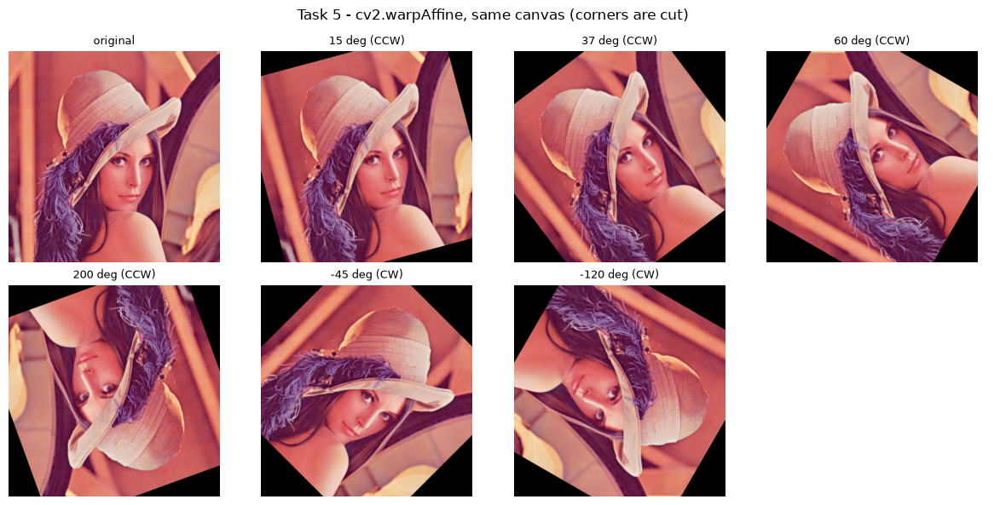

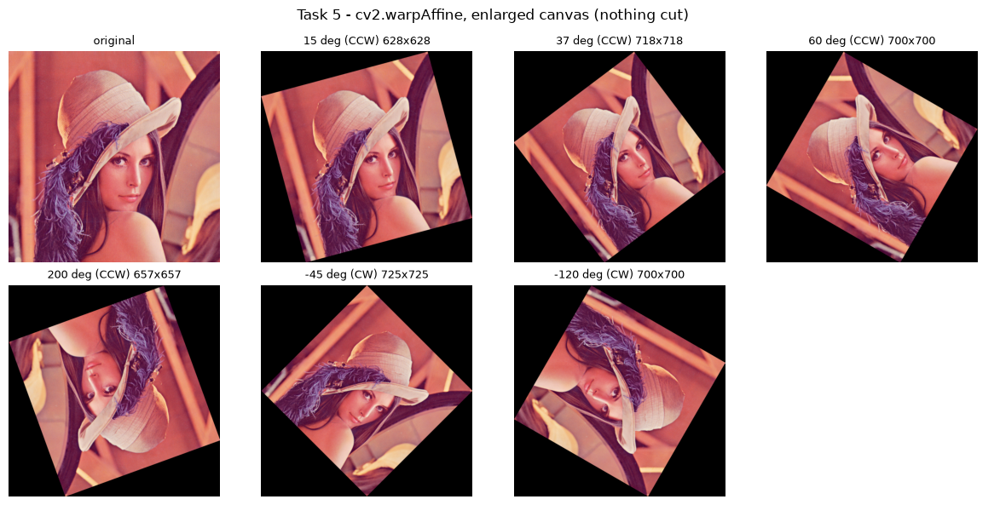

In [18]:
angles = [15, 37, 60, 200, -45, -120]       # positive = counterclockwise, negative = clockwise
items_cut = [('original', lena)]
items_full = [('original', lena)]
for ang in angles:
    direction = 'CCW' if ang > 0 else 'CW'
    rot = rotate_cv(lena, ang)
    rot_full = rotate_cv(lena, ang, keep_all=True)
    items_cut.append((f'{ang} deg ({direction})', rot))
    items_full.append((f'{ang} deg ({direction}) {rot_full.shape[1]}x{rot_full.shape[0]}', rot_full))
    print(f'{ang:5d} deg ({direction:3s}) enlarged canvas {rot_full.shape[1]}x{rot_full.shape[0]}')

show_grid(items_cut, cols=4, title='Task 5 - cv2.warpAffine, same canvas (corners are cut)')
show_grid(items_full, cols=4, title='Task 5 - cv2.warpAffine, enlarged canvas (nothing cut)')

Angles +15, +37, +60, +200 turn counterclockwise and -45, -120 clockwise. On the same canvas the corners are cut;
the enlarged canvas (`|w cos| + |h sin|`, `|w sin| + |h cos|`) keeps everything: 15 deg -> 628x628, 37 -> 718x718,
60 -> 700x700, 200 -> 657x657, -45 -> 725x725, -120 -> 700x700.

#### 5.1 **Own numpy rotation vs OpenCV**

own rotation matrix == cv2.getRotationMatrix2D: True


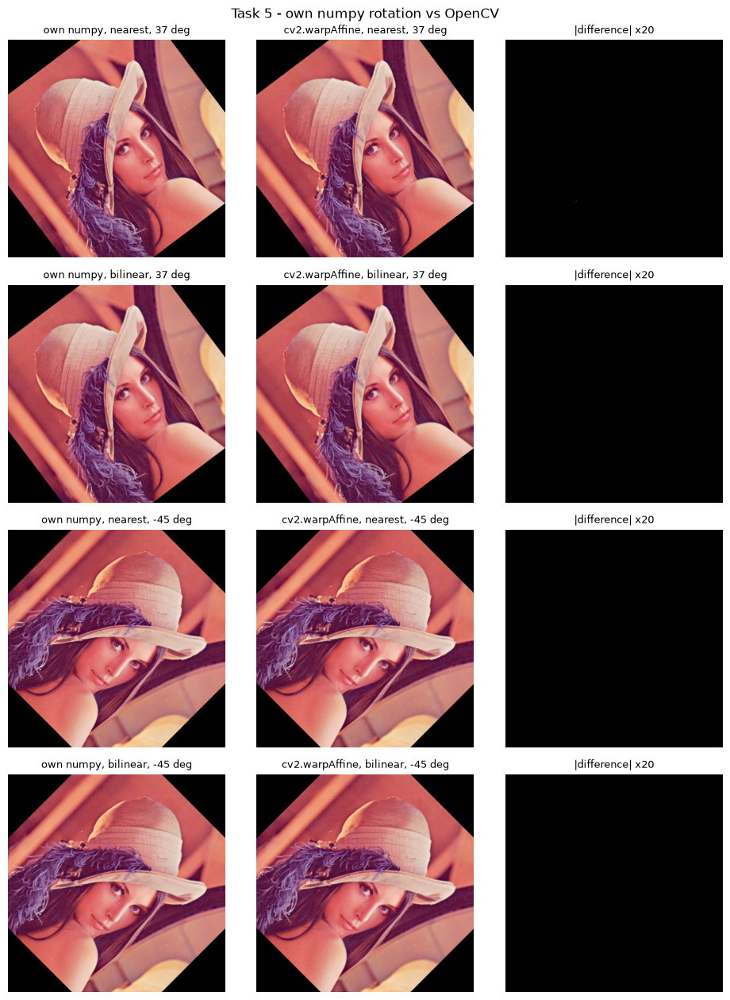

| angle | interpolation | mean abs diff | max abs diff | identical pixels (%) |
|---|---|---|---|---|
| 37 | nearest | 0.000 | 29 | 100.00 |
| 37 | bilinear | 0.000 | 1 | 99.97 |
| -45 | nearest | 0.000 | 0 | 100.00 |
| -45 | bilinear | 0.000 | 1 | 99.98 |

In [19]:
M_mine = rotation_matrix(37, image_center(lena))
M_cv = cv2.getRotationMatrix2D(image_center(lena), 37, 1.0)
print('own rotation matrix == cv2.getRotationMatrix2D:', np.allclose(M_mine, M_cv))

rows = []
compare_items = []
for ang in (37, -45):
    for interp, flag in (('nearest', cv2.INTER_NEAREST), ('bilinear', cv2.INTER_LINEAR)):
        mine = rotate_numpy(lena, ang, interp)
        ref = rotate_cv(lena, ang, flags=flag)
        diff = cv2.absdiff(mine, ref)
        identical = (diff.max(axis=2) == 0).mean() * 100
        rows.append({
            'angle': ang,
            'interpolation': interp,
            'mean abs diff': f'{diff.mean():.3f}',
            'max abs diff': int(diff.max()),
            'identical pixels (%)': f'{identical:.2f}',
        })
        compare_items += [(f'own numpy, {interp}, {ang} deg', mine),
                          (f'cv2.warpAffine, {interp}, {ang} deg', ref),
                          ('|difference| x20', np.clip(diff.astype(np.int32) * 20, 0, 255).astype(np.uint8))]

show_grid(compare_items, cols=3, title='Task 5 - own numpy rotation vs OpenCV', cell=3.2)
show_table(rows)

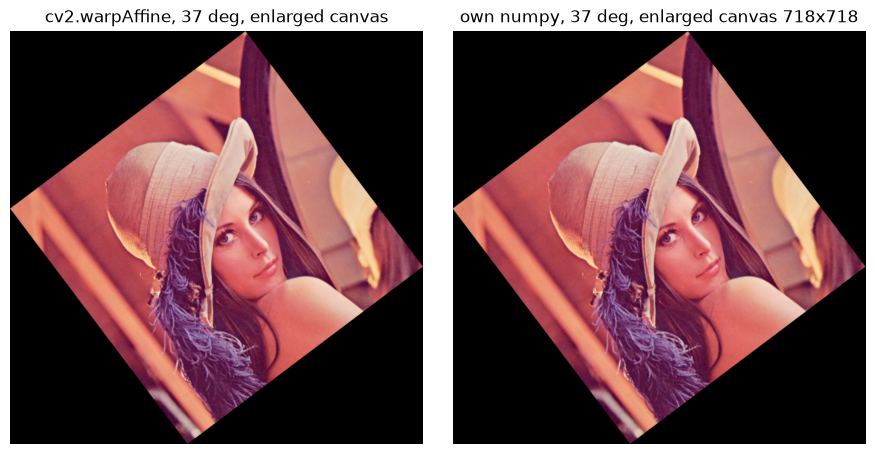

In [20]:
own_full = rotate_numpy(lena, 37, 'bilinear', keep_all=True)

fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
axs[0].imshow(to_rgb(rotate_cv(lena, 37, keep_all=True)))
axs[0].set_title('cv2.warpAffine, 37 deg, enlarged canvas')
axs[1].imshow(to_rgb(own_full))
axs[1].set_title(f'own numpy, 37 deg, enlarged canvas {own_full.shape[1]}x{own_full.shape[0]}')
for ax in axs:
    ax.axis('off')
plt.tight_layout()
plt.show()

My 2x3 matrix equals `cv2.getRotationMatrix2D` (`np.allclose` -> True) and the images look identical.
Nearest: 100.00 % identical pixels (37 deg has a max difference of 29 on a handful of pixels that fall exactly half-way
between two neighbours: OpenCV rounds in 1/32-pixel fixed point, I round in floating point).
Bilinear: 99.97 % (37 deg) and 99.98 % (-45 deg) identical, max difference 1 gray level (OpenCV uses integer weights).

#### 5.2 **Interpolation methods (same 30 degree rotation)**

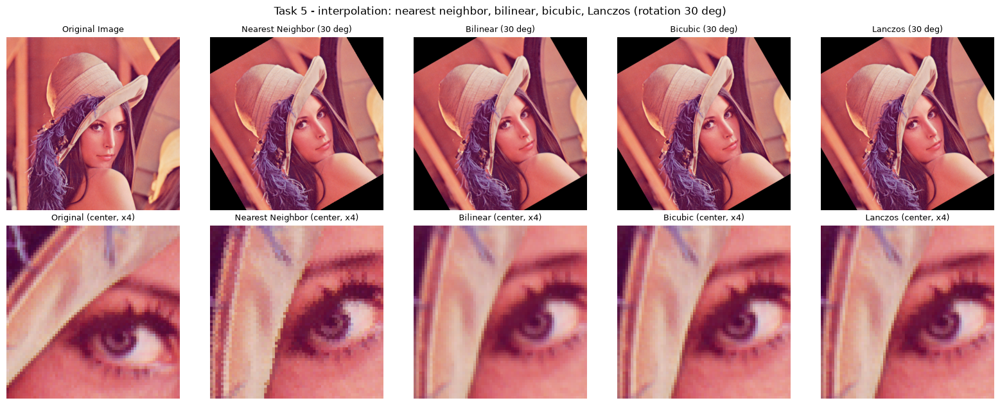

| interpolation | flag | sharpness (var. Laplacian) |
|---|---|---|
| Nearest Neighbor | 0 | 909 |
| Bilinear | 1 | 281 |
| Bicubic | 2 | 399 |
| Lanczos | 4 | 429 |

In [21]:
angle = 30
center = (lena.shape[1] // 2, lena.shape[0] // 2)
M_30 = cv2.getRotationMatrix2D(center, angle, 1.0)
w, h = lena.shape[1], lena.shape[0]
interpolations = [('Nearest Neighbor', cv2.INTER_NEAREST), ('Bilinear', cv2.INTER_LINEAR),
                  ('Bicubic', cv2.INTER_CUBIC), ('Lanczos', cv2.INTER_LANCZOS4)]
items = [('Original Image', lena)]
zoom_items = [('Original (center, x4)', zoom_center(lena))]
rows = []
for name, flag in interpolations:
    rotated = cv2.warpAffine(lena, M_30, (w, h), flags=flag)
    items.append((f'{name} (30 deg)', rotated))
    zoom_items.append((f'{name} (center, x4)', zoom_center(rotated)))
    gray = cv2.cvtColor(rotated, cv2.COLOR_BGR2GRAY)
    rows.append({'interpolation': name, 'flag': flag,
                 'sharpness (var. Laplacian)': int(round(float(cv2.Laplacian(gray, cv2.CV_64F).var()), 0))})

show_grid(items + zoom_items, cols=5, cell=3.2,
          title='Task 5 - interpolation: nearest neighbor, bilinear, bicubic, Lanczos (rotation 30 deg)')
show_table(rows)

- Nearest neighbour **909**: jagged "staircase" edges; the high number measures the jaggedness, not detail.
- Bilinear **281**: smooth but a bit soft (4 pixels averaged). Bicubic **399**: smooth and sharper (16 pixels).
- Lanczos **429**: the sharpest smooth result, the slowest one, and it can ring near strong edges.

**How can an image rotation function be implemented?**
1. Pick the center `c` (normally the image center) and the angle, and build `M = [R | t]` with
   `R = [[cos, sin], [-sin, cos]]` and `t = c - R c`, so the center stays in place (`cv2.getRotationMatrix2D`).
2. Do not push input pixels forward (rotated positions are not integers, the output would get holes); use
   **inverse mapping**: for every output pixel `(x, y)` compute the source `(sx, sy) = M^-1 * (x, y, 1)`.
3. **Interpolate** the input at `(sx, sy)`: nearest neighbour (fast, jagged), bilinear (4 pixels, smooth), bicubic (16 pixels).
4. If `(sx, sy)` falls outside the input, write a border value (black) or replicate the border.
5. To keep the whole image, compute the bigger canvas (`|w cos| + |h sin|`, `|w sin| + |h cos|`) and add the offset to `t`.

---

### 6. **Crop a rectangle: crop(img, top, left, width, height)**

`crop` returns `img[top:top+height, left:left+width]`, clipped to the image, so a request that goes outside the image
does not crash. Green boxes = the requested rectangles.

face           requested 180x180 at (top=230, left=220) -> got 180x180
hat            requested 300x180 at (top=20, left=100) -> got 300x180
out_of_bounds  requested 300x300 at (top=400, left=400) -> got 112x112


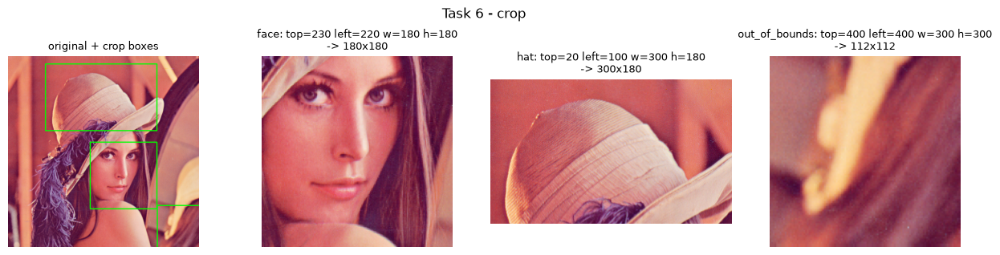

In [22]:
# Rectangle that starts at pixel (top, left) with the given width (columns) and height (rows),
# clipped to the image so a region outside the image does not crash
def crop(img, top, left, width, height):
    h, w = img.shape[:2]
    y1, x1 = max(top, 0), max(left, 0)
    y2, x2 = min(top + height, h), min(left + width, w)
    if y2 <= y1 or x2 <= x1:
        return img[0:0, 0:0]            # empty crop
    return img[y1:y2, x1:x2].copy()


requests = [('face', 230, 220, 180, 180),
            ('hat', 20, 100, 300, 180),
            ('out_of_bounds', 400, 400, 300, 300)]
boxed = lena.copy()
items = [('original + crop boxes', boxed)]
for name, top, left, width, height in requests:
    part = crop(lena, top, left, width, height)
    cv2.rectangle(boxed, (left, top), (left + width - 1, top + height - 1), (0, 255, 0), 2)
    items.append((f'{name}: top={top} left={left} w={width} h={height}\n-> {part.shape[1]}x{part.shape[0]}', part))
    print(f'{name:14s} requested {width}x{height} at (top={top}, left={left}) -> got {part.shape[1]}x{part.shape[0]}')

show_grid(items, cols=4, title='Task 6 - crop', cell=3.2)

`face` (180x180 at top=230, left=220) and `hat` (300x180 at top=20, left=100) come back exactly as requested.
`out_of_bounds` asks for 300x300 at top=400, left=400 and gets **112x112**: it is clipped to the 512x512 image instead of crashing.

---

### 7. **Emoji drawn with OpenCV (saved as iancu_stefan_teodor.jpg)**

saved iancu_stefan_teodor.jpg: True


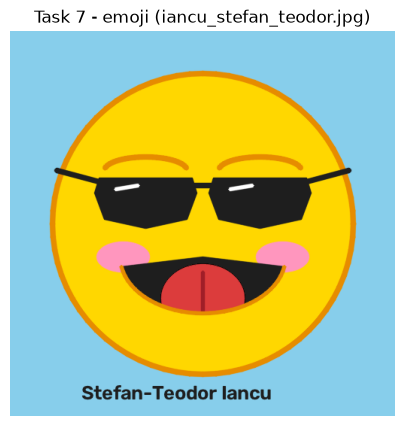

In [23]:
size = 512
canvas = np.full((size, size, 3), (235, 206, 135), np.uint8)     # light sky blue background (BGR)
yellow, orange, black, white = (0, 215, 255), (0, 140, 230), (30, 30, 30), (255, 255, 255)
red, pink, dark_red = (60, 60, 220), (190, 150, 255), (40, 30, 160)
center = (size // 2, size // 2)
aa = cv2.LINE_AA

# face
cv2.circle(canvas, center, 200, yellow, -1, aa)
cv2.circle(canvas, center, 200, orange, 6, aa)

# cheeks (blush)
cv2.ellipse(canvas, (150, 300), (35, 20), 0, 0, 360, pink, -1, aa)
cv2.ellipse(canvas, (362, 300), (35, 20), 0, 0, 360, pink, -1, aa)

# open mouth with tongue
cv2.ellipse(canvas, (256, 300), (110, 75), 0, 10, 170, black, -1, aa)
tongue = np.zeros_like(canvas)
cv2.ellipse(tongue, (256, 355), (55, 45), 0, 0, 360, red, -1, aa)
cv2.line(tongue, (256, 320), (256, 395), dark_red, 3, aa)
mouth_mask = np.zeros((size, size), np.uint8)
cv2.ellipse(mouth_mask, (256, 300), (110, 75), 0, 10, 170, 255, -1, aa)
canvas = np.where((mouth_mask[..., None] > 0) & (tongue.sum(axis=2, keepdims=True) > 0), tongue, canvas)
cv2.ellipse(canvas, (256, 300), (110, 75), 0, 10, 170, orange, 4, aa)

# sunglasses: two rounded lenses (polygons), a bridge and two arms
for cx in (180, 332):
    lens = np.array([[cx - 62, 195], [cx + 62, 195], [cx + 68, 215], [cx + 55, 250],
                     [cx, 262], [cx - 55, 250], [cx - 68, 215]], np.int32)
    cv2.fillPoly(canvas, [lens], black, aa)
    cv2.line(canvas, (cx - 40, 210), (cx - 10, 205), white, 3, aa)      # reflection
cv2.line(canvas, (242, 205), (270, 205), black, 6, aa)                   # bridge
cv2.line(canvas, (118, 200), (62, 185), black, 6, aa)                    # left arm
cv2.line(canvas, (394, 200), (450, 185), black, 6, aa)                   # right arm

# eyebrows peeking above the glasses
cv2.ellipse(canvas, (180, 185), (55, 18), 0, 190, 350, orange, 5, aa)
cv2.ellipse(canvas, (332, 185), (55, 18), 0, 190, 350, orange, 5, aa)

# name tag
cv2.putText(canvas, 'Stefan-Teodor Iancu', (95, 490), cv2.FONT_HERSHEY_SIMPLEX, 0.9, black, 2, aa)

# the deliverable file for the end-of-semester archive
ok = cv2.imwrite('iancu_stefan_teodor.jpg', canvas, [cv2.IMWRITE_JPEG_QUALITY, 95])
print('saved iancu_stefan_teodor.jpg:', ok)

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(to_rgb(canvas))
ax.set_title('Task 7 - emoji (iancu_stefan_teodor.jpg)')
ax.axis('off')
plt.show()

A 512x512 drawing made only with `cv2.circle`, `cv2.ellipse`, `cv2.line`, `cv2.fillPoly` and `cv2.putText`:
yellow face with an orange outline, pink cheeks, open mouth with a red tongue, black sunglasses with white
reflections, eyebrows and my name. Saved next to this notebook as `iancu_stefan_teodor.jpg` (JPEG quality 95).

---

### 8. **A short essay about ethics in Computer Vision**

The essay (`ethics_essay.md`, about 590 words) uses the two papers given in the lab: R. Waelen,
*The ethics of computer vision: an overview in terms of power* (AI and Ethics, 2023) and L. Munn,
*The uselessness of AI ethics* (AI and Ethics, 2022).

> #### Ethics in Computer Vision - a short essay
>
> *Stefan-Teodor Iancu, Lab 1 (Vedere artificiala)*
>
> Computer vision gives machines the power to see. A camera plus a model can now find a face in a crowd, guess a person's age or mood, read a license plate or follow someone from street to street. This is useful: it helps doctors read scans and helps cars avoid people. But the same power can hurt people, and the two papers I read for this lab show two sides of the problem: what the harms are, and why the usual answer to them (ethics principles) is weak.
>
> ##### Seeing is power
>
> Rosalie Waelen, in *The ethics of computer vision: an overview in terms of power* (AI and Ethics, 2023), does not start from abstract values like "fairness". She starts from power. When a system can watch and label people, the people who own the system gain power, and the people being watched lose some. People lose control over their own information and their anonymity in public spaces. A camera network changes how we behave even when nobody is actually watching; we stop doing things we have every right to do, because we might be seen. This is the "chilling effect" of surveillance. Waelen also notes that computer vision lets a machine decide who we are: our gender, our emotion, whether we look "suspicious". This takes away our ability to tell our own story. Emotion recognition is built on a shaky theory that faces show the same emotions everywhere, yet it is sold to schools and employers as if it were a fact.
>
> ##### Bias, consent and fake images
>
> Face recognition is where these problems are most visible. The famous *Gender Shades* study showed that commercial systems made far more mistakes on dark-skinned women than on light-skinned men. The reason is not magic: the training datasets had mostly light-skinned male faces. A biased dataset gives a biased model, and when the police use such a model, the mistakes fall on the groups that already have the least power.
>
> Datasets raise a second question: consent. Many large face datasets were scraped from the internet. The people in those photos never agreed to train a surveillance model. Finally, the same generative models that help us create images can create deepfakes: fake videos of real people saying or doing things they never did. This harms individuals and makes it harder for everyone to trust what they see.
>
> ##### Do ethics statements change anything?
>
> Luke Munn, in *The uselessness of AI ethics* (AI and Ethics, 2022), argues that the flood of "AI principles" published by companies and governments is mostly useless. He gives three reasons. The principles are meaningless, because words like "fairness" can mean anything, so everyone agrees and nothing changes. They are isolated, because engineers are trained to optimize metrics, not to think about society. And they are toothless, because breaking them has no consequence. A company can publish an ethics charter and sell face recognition to the police the same week. Munn suggests two better paths: think more broadly about justice and who gets hurt, and think more narrowly about concrete things that can be checked, such as accuracy on every group, audits and real regulation.
>
> ##### My opinion
>
> I agree with both papers. As a student I can already see how easy it is to download a face dataset, train a model and never ask who is in the data or who will use the result. Good intentions are not enough. What helps is concrete: measure errors per group, document where data came from, refuse clearly harmful uses, and support laws that have teeth. Computer vision should make the world easier to see for everyone, not easier to watch for a few.

#### Optional: an image that "says more than 1000 words"

**"Earthrise"** (NASA, Apollo 8, 24 December 1968, William Anders): the small blue-and-white Earth rising over the
gray surface of the Moon. Without a word it says that the whole planet, with all its borders and wars, is one small
fragile place in a black void. It is a NASA photo, so it is in the public domain.

---

### Conclusions

- Blur filters trade noise for detail; the right filter depends on the noise. The median filter is the best match for
  salt-and-pepper noise (18.5 -> 34.8 dB) because it is non-linear and keeps the edges.
- Sharpening adds the edges back. For the kernel `w`, a = 1 is the best general choice: the kernel sums to 1, so the
  brightness stays the same and only the edges are boosted.
- For a color image, equalize only the brightness channel (V or L), not R, G, B separately; CLAHE adds local contrast
  without blowing out the bright areas.
- Rotation = inverse mapping + interpolation. My numpy version matches `cv2.warpAffine` (same matrix, at most 1 gray
  level of difference with bilinear interpolation).
- uint8 filter results saturate silently at 0 and 255; use a float depth when the negative values matter.